In [ ]:
!pip install "darts[all]"

In [40]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from darts import TimeSeries
from darts.utils.timeseries_generation import gaussian_timeseries, linear_timeseries, sine_timeseries
from darts.models import RandomForest, XGBModel, LightGBMModel, CatBoostModel
from darts.metrics import mape, smape, mae
from darts.dataprocessing.transformers import Scaler
from darts.utils.timeseries_generation import datetime_attribute_timeseries
from darts.datasets import AirPassengersDataset, MonthlyMilkDataset, ElectricityDataset
import warnings
warnings.filterwarnings('ignore')

In [5]:
series_air = AirPassengersDataset().load()
series_air

,#Passengers
Month,
1949-01-01,112.0
1949-02-01,118.0
1949-03-01,132.0
1949-04-01,129.0
1949-05-01,121.0
...,...
1960-08-01,606.0
1960-09-01,508.0
1960-10-01,461.0


In [6]:
series_milk = MonthlyMilkDataset().load()
series_milk

,Pounds per cow
Month,
1962-01-01,589.0
1962-02-01,561.0
1962-03-01,640.0
1962-04-01,656.0
1962-05-01,727.0
...,...
1975-08-01,858.0
1975-09-01,817.0
1975-10-01,827.0


<Axes: xlabel='Month'>

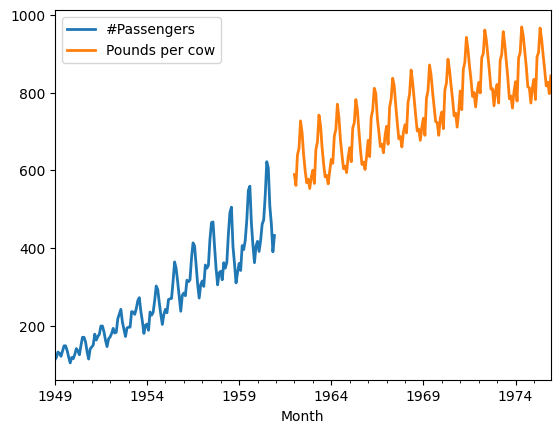

In [8]:
series_air.plot()
series_milk.plot()

<Axes: xlabel='Month'>

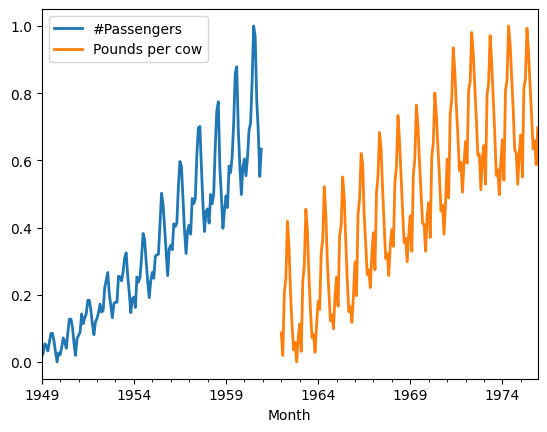

In [9]:
scaler_air, scaler_milk = Scaler(), Scaler()
series_air_scaled = scaler_air.fit_transform(series_air)
series_milk_scaled = scaler_milk.fit_transform(series_milk)
series_air_scaled.plot()
series_milk_scaled.plot()

In [10]:
# train, validation 데이터 분리
train_air, val_air = series_air_scaled[:-36], series_air_scaled[-36:]
train_milk, val_milk = series_milk_scaled[:-36], series_milk_scaled[-36:]

In [11]:
# lookback period=24, forecast_period=12인 단변량 시계열 모형
RF_air = RandomForest(lags=24, output_chunk_length=12)
RF_air.fit(train_air)

RandomForest(lags=24, lags_past_covariates=None, lags_future_covariates=None, output_chunk_length=12, output_chunk_shift=0, add_encoders=None, n_estimators=100, max_depth=None, multi_models=True, use_static_covariates=True, random_state=None)

MAPE = 21.95%


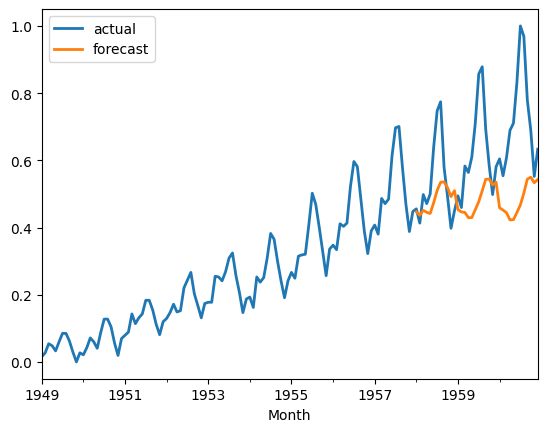

In [15]:
# 자기회귀(autoregressive) 방식으로 예측(오차 누적됨)
pred = RF_air.predict(n=36)
series_air_scaled.plot(label='actual')
pred.plot(label='forecast')
print(f'MAPE = {mape(series_air_scaled, pred):.2f}%')

In [17]:
# 다중시계열 global 모형
RF_air_milk = RandomForest(lags=24, output_chunk_length=12)
RF_air_milk.fit([train_air, train_milk])

RandomForest(lags=24, lags_past_covariates=None, lags_future_covariates=None, output_chunk_length=12, output_chunk_shift=0, add_encoders=None, n_estimators=100, max_depth=None, multi_models=True, use_static_covariates=True, random_state=None)

MAPE = 9.96%


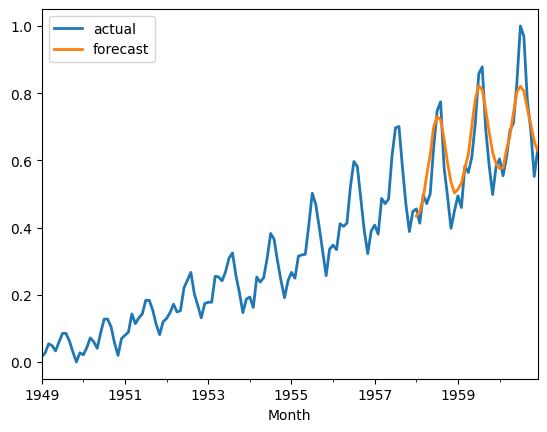

In [18]:
pred = RF_air_milk.predict(n=36, series=train_air)
series_air_scaled.plot(label='actual')
pred.plot(label='forecast')
print(f'MAPE = {mape(series_air_scaled, pred):.2f}%')

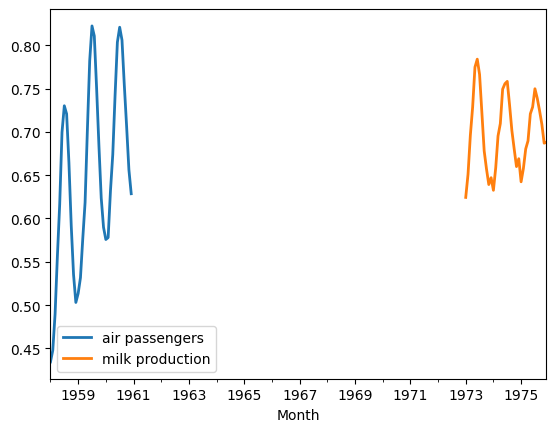

In [19]:
pred_list = RF_air_milk.predict(n=36, series=[train_air, train_milk])
for series, label in zip(pred_list, ['air passengers', 'milk production']):
    series.plot(label=label)

Text(0.5, 1.0, 'Milk(year and month)')

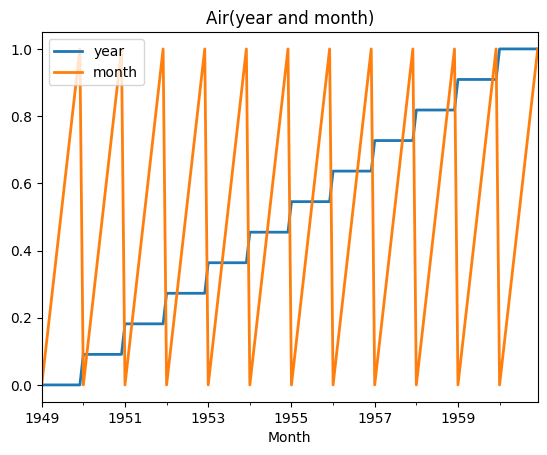

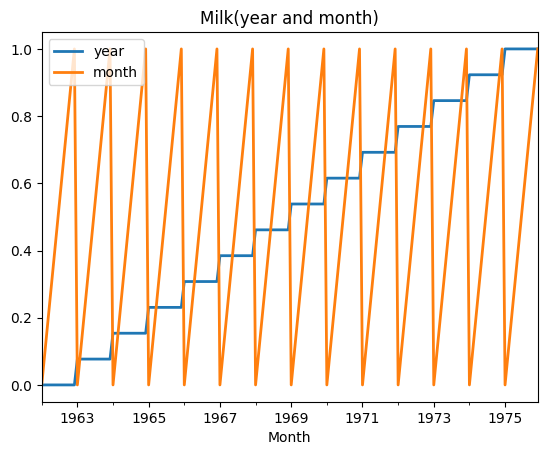

In [26]:
# 추세를 반영하지 못하는 앙상블의 약점을 보완하기 위해 datetime_attribute_timeseries를 이용해 공변량 추가
# 시계열과 마찬가지로 year, month stack -> scale -> train/val
air_year = datetime_attribute_timeseries(series_air_scaled, attribute='year')
air_month = datetime_attribute_timeseries(series_air_scaled, attribute='month')
milk_year = datetime_attribute_timeseries(series_milk_scaled, attribute='year')
milk_month = datetime_attribute_timeseries(series_milk_scaled, attribute='month')
air_covariates = air_year.stack(air_month)
milk_covariates = milk_year.stack(milk_month)

scaler_dt_air = Scaler()
air_covariates = scaler_dt_air.fit_transform(air_covariates)
scaler_dt_milk = Scaler()
milk_covariates = scaler_dt_milk.fit_transform(milk_covariates)

air_train_covariates, air_val_covariates = air_covariates[:-36], air_covariates[-36:]
milk_train_covariates, milk_val_covariates = milk_covariates[:-36], milk_covariates[36:]

plt.figure()
air_covariates.plot()
plt.title('Air(year and month)')

plt.figure()
milk_covariates.plot()
plt.title('Milk(year and month)')

In [31]:
# 공변량을 반영하여 모델 만들기
# input: lookback period=24, 공변량도 과거 -24 시점부터 -1시점까지
# output: forecast period=12
rf_pastcov = RandomForest(lags=24, lags_past_covariates=24, output_chunk_length=12)
rf_pastcov.fit(series=[train_air, train_milk],
               past_covariates=[air_train_covariates, milk_train_covariates])

xgb_pastcov = XGBModel(lags=24, lags_past_covariates=24, output_chunk_length=12)
xgb_pastcov.fit(series=[train_air, train_milk],
                past_covariates=[air_train_covariates, milk_train_covariates])

lgbm_pastcov = LightGBMModel(lags=24, lags_past_covariates=24, output_chunk_length=12, verbose=-1)
lgbm_pastcov.fit(series=[train_air, train_milk],
                past_covariates=[air_train_covariates, milk_train_covariates])

# cat_pastcov = CatBoostModel(lags=24, lags_past_covariates=24, output_chunk_length=12)
# cat_pastcov.fit(series=[train_air, train_milk],
#                 past_covariates=[air_train_covariates, milk_train_covariates])

LightGBMModel(lags=24, lags_past_covariates=24, lags_future_covariates=None, output_chunk_length=12, output_chunk_shift=0, add_encoders=None, likelihood=None, quantiles=None, random_state=None, multi_models=True, use_static_covariates=True, categorical_past_covariates=None, categorical_future_covariates=None, categorical_static_covariates=None, verbose=-1)

In [33]:
def plot_air_results(model, n, series, past_covariates):
    pred_cov = model.predict(n=n, series=series, past_covariates=past_covariates)
    series_air_scaled.plot(label='actual')
    pred_cov.plot(label='forecast')

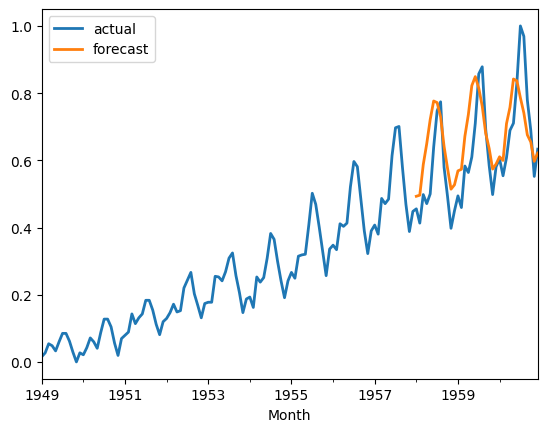

In [34]:
plot_air_results(rf_pastcov, 36, train_air, air_covariates)

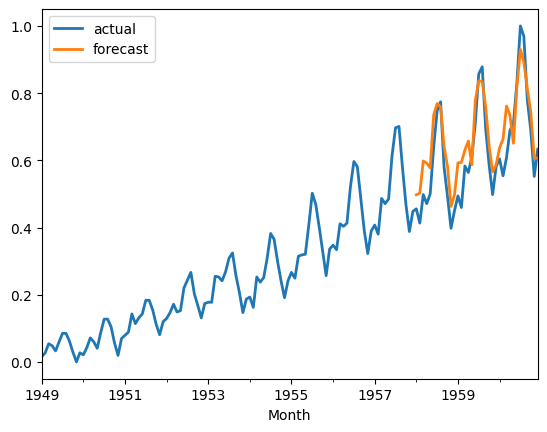

In [35]:
plot_air_results(xgb_pastcov, 36, train_air, air_covariates)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/v

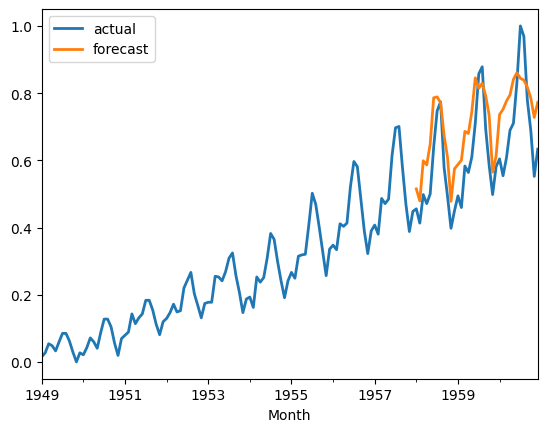

In [36]:
plot_air_results(lgbm_pastcov, 36, train_air, air_covariates)

In [41]:
# 교차검증: historical_forecast()
# start=0.6: 시계열 앞쪽 60% 지점부터 백테스트 시작
# forecast_horizon=12: forecast period=12
# stride=1: 1개월씩 밀면서 검증
backtest_rf = rf_pastcov.historical_forecasts(series_air_scaled, past_covariates=air_covariates,
                                              start=0.6, forecast_horizon=12, stride=1, retrain=False)
print(f'MAPE(RandomForest)={mape(series_air_scaled, backtest_rf):.2f}%')

backtest_xgb = xgb_pastcov.historical_forecasts(series_air_scaled, past_covariates=air_covariates,
                                              start=0.6, forecast_horizon=12, stride=1, retrain=False)
print(f'MAPE(XGBoost)={mape(series_air_scaled, backtest_xgb):.2f}%')

backtest_lgbm = lgbm_pastcov.historical_forecasts(series_air_scaled, past_covariates=air_covariates,
                                              start=0.6, forecast_horizon=12, stride=1, retrain=False)
print(f'MAPE(LightGBM)={mape(series_air_scaled, backtest_lgbm):.2f}%')

MAPE(RandomForest)=13.21%
MAPE(XGBoost)=5.83%
MAPE(LightGBM)=8.32%


In [42]:
# 다변량 시계열 모형(ElectricityDataset)
multi_series_elec = ElectricityDataset().load()
multi_series_elec

,MT_001,MT_002,MT_003,MT_004,MT_005,...,MT_366,MT_367,MT_368,MT_369,MT_370
Unnamed: 0,,,,,,,,,,,
2011-01-01 00:15:00,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000
2011-01-01 00:30:00,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000
2011-01-01 00:45:00,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000
2011-01-01 01:00:00,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000
2011-01-01 01:15:00,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000
...,...,...,...,...,...,...,...,...,...,...,...
2014-12-31 23:00:00,2.538071,22.048364,1.737619,150.406504,85.365854,...,5.851375,697.102722,176.961603,651.026393,7621.621622
2014-12-31 23:15:00,2.538071,21.337127,1.737619,166.666667,81.707317,...,9.947338,671.641791,168.614357,669.354839,6702.702703
2014-12-31 23:30:00,2.538071,20.625889,1.737619,162.601626,82.926829,...,9.362200,670.763828,153.589316,670.087977,6864.864865


In [43]:
# 15분 단위 frequency를 1시간 단위로 resample하고 마지막 7일만 사용함
retained_components = ['MT_002', 'MT_008', 'MT_009']
multi_series_elec = multi_series_elec[retained_components]
multi_series_elec = multi_series_elec.resample(freq='1H')

In [45]:
multi_series_elec = multi_series_elec[-168:]

<Axes: xlabel='time'>

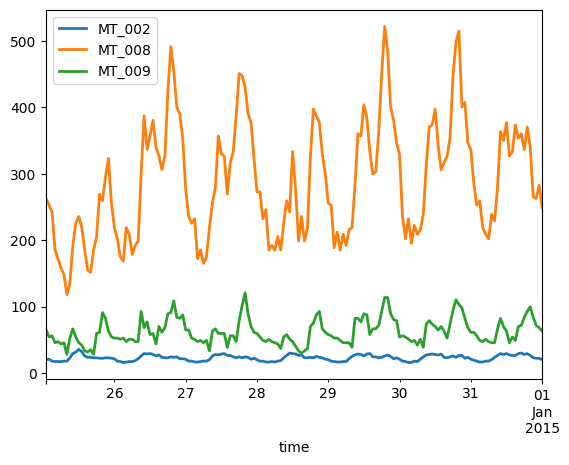

In [50]:
# TimeSeries를 dataframe으로 변환해서 index 이름을 'time'으로 하고 다시 TimeSeries로 변경
multi_pd = multi_series_elec.to_dataframe()
multi_pd.index.name = 'time'
multi_series_elec = TimeSeries.from_dataframe(multi_pd)
multi_series_elec.plot()

In [51]:
# train/validation set 구분
# scale
train_elec, val_elec = multi_series_elec[:-24], multi_series_elec[-24:]

# 학습데이터에만 fit() 적용, data leakage 방지를 위해 검증데이터에는 transform()만 적용
scaler_elec = Scaler()
train_elec_scaled = scaler_elec.fit_transform(train_elec)
val_elec_scaled = scaler_elec.transform(val_elec)

def fit_and_pred(model, train, val):
    model.fit(train)
    pred = model.predict(len(val))
    return pred

In [58]:
model_rf = RandomForest(lags=24)
model_xgb = XGBModel(lags=24)
model_lgbm = LightGBMModel(lags=24)

pred_rf = fit_and_pred(model_rf, train_elec_scaled, val_elec_scaled)
print(f'MAE(RF)={mae(val_elec_scaled, pred_rf):.3f}')
pred_xgb = fit_and_pred(model_xgb, train_elec_scaled, val_elec_scaled)
print(f'MAE(XGBoost)={mae(val_elec_scaled, pred_xgb):.3f}')
pred_lgbm = fit_and_pred(model_lgbm, train_elec_scaled, val_elec_scaled)
print(f'MAE(LGBM)={mae(val_elec_scaled, pred_lgbm):.3f}')

MAE(RF)=0.075
MAE(XGBoost)=0.090
MAE(LGBM)=0.089


<Axes: xlabel='time'>

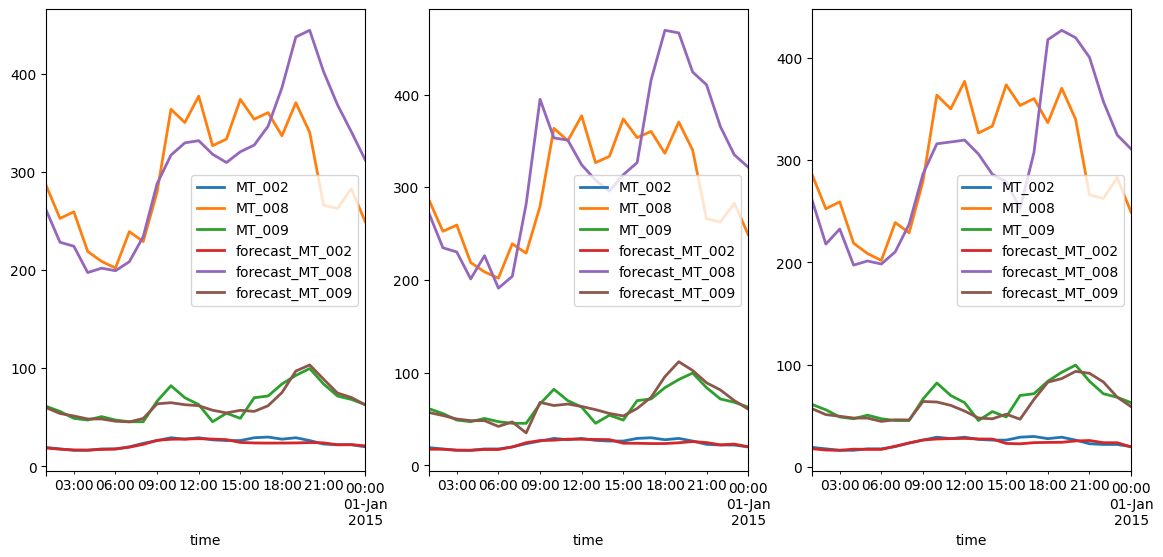

In [61]:
# 예측치를 원래 scale로 환원시킨 후, 실제와 예측치 plot
forecast_rf = scaler_elec.inverse_transform(pred_rf)
forecast_xgb = scaler_elec.inverse_transform(pred_xgb)
forecast_lgbm = scaler_elec.inverse_transform(pred_lgbm)

labels = [f'forecast_{c}' for c in retained_components]
fig, axes = plt.subplots(1, 3, figsize=(14, 6))
val_elec.plot(ax=axes[0])
forecast_rf.plot(label=labels, ax=axes[0])
val_elec.plot(ax=axes[1])
forecast_xgb.plot(label=labels, ax=axes[1])
val_elec.plot(ax=axes[2])
forecast_lgbm.plot(label=labels, ax=axes[2])